# Example 3.1: Chromosome Representation and Basic Operators
**Chapter 3 · Four Bar Mechanisms with Genetic Algorithms**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Encode an individual from the four-bar design space as a vector of three genes `(a, b, c)` with a fixed `d = 85 mm`. Implement the genetic operators of **arithmetic crossover** and **Gaussian mutation**, apply them to two example parent individuals, and visualize the effect on the genes.

**Objective:** Understand how a mechanism is represented and manipulated in the GA search space.

In [5]:
# ── Imports ─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [6]:
# ── Chromosome representation ──────────────────────────────────────────
random.seed(42)

BOUNDS_MIN, BOUNDS_MAX = 10., 120.
D_FIJO = 85.   # fixed link [mm]

def crear_individuo():
    """Individual: chromosome [a, b, c] with uniform values in [BOUNDS_MIN, BOUNDS_MAX]."""
    return random.uniform(BOUNDS_MIN, BOUNDS_MAX, 3)

def cruce_aritmetico(padre1, padre2, alpha=None):
    """Arithmetic crossover: child_i = α·p1_i + (1-α)·p2_i."""
    if alpha is None:
        alpha = random.uniform(0, 1)
    hijo1 = alpha * padre1 + (1 - alpha) * padre2
    hijo2 = (1 - alpha) * padre1 + alpha * padre2
    return clip(hijo1, BOUNDS_MIN, BOUNDS_MAX), \
           clip(hijo2, BOUNDS_MIN, BOUNDS_MAX)

def mutacion_gaussiana(individuo, pm=0.1, sigma=5.0):
    """Gaussian mutation: each gene mutates with probability pm."""
    mutante = individuo.copy()
    mascara = random.rand(len(individuo)) < pm
    mutante[mascara] += random.normal(0, sigma, mascara.sum())
    return clip(mutante, BOUNDS_MIN, BOUNDS_MAX)

# ── Demo ──────────────────────────────────────────────────────────
p1 = crear_individuo()
p2 = crear_individuo()
h1, h2 = cruce_aritmetico(p1, p2, alpha=0.6)
h1m = mutacion_gaussiana(h1, pm=0.3)

print("Parent 1 (a,b,c):", around(p1, 2))
print("Parent 2 (a,b,c):", around(p2, 2))
print("Child 1  (α=0.6):", around(h1, 2))
print("Child 1 mutated: ", around(h1m, 2))
print("Mutated genes:  ", sum(h1m != h1), "out of", len(h1))




Parent 1 (a,b,c): [ 51.2  114.58  90.52]
Parent 2 (a,b,c): [75.85 27.16 27.16]
Child 1  (α=0.6): [61.06 79.61 65.18]
Child 1 mutated:  [58.16 79.61 65.18]
Mutated genes:   1 out of 3


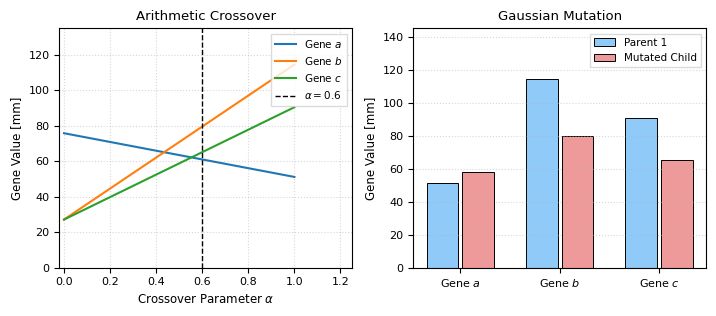

In [7]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Automated Naming Setup
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_3_1_chromosome_basic_operators"
except Exception:
    notebook_name = "Figure_3_1_chromosome_basic_operators"

# 2. Springer Styling and Professional Typography
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8,
    'axes.labelsize': 8.5,
    'axes.titlesize': 9.5,
    'legend.fontsize': 7.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})

# 3. Figure Creation with Compact Layout
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))

# --- Left Subplot: Arithmetic Crossover ---
a_vals = np.linspace(0, 1, 50)
gene_labels = [r'Gene $a$', r'Gene $b$', r'Gene $c$']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for g1, g2, label, col in zip(p1, p2, gene_labels, colors):
    # Reconstructing the crossover parameter formula (alpha*g1 + (1-alpha)*g2)
    axes[0].plot(a_vals, a_vals * g1 + (1 - a_vals) * g2, lw=1.5, label=label, color=col)

axes[0].axvline(0.6, color='black', ls='--', lw=1, label=r'$\alpha = 0.6$')
axes[0].set_xlabel(r'Crossover Parameter $\alpha$')
axes[0].set_ylabel('Gene Value [mm]')
axes[0].set_title('Arithmetic Crossover')
axes[0].grid(True, linestyle=':', alpha=0.5)
# Expand limits to avoid overlaps with the legend
axes[0].set_xlim(-0.02, 1.25)
axes[0].set_ylim(0, 135)
axes[0].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='lightgray')

# --- Right Subplot: Gaussian Mutation ---
axes[1].bar(np.arange(3) - 0.18, p1, 0.32, label='Parent 1', color='#90CAF9', edgecolor='black', linewidth=0.7)
axes[1].bar(np.arange(3) + 0.18, h1m, 0.32, label='Mutated Child', color='#EF9A9A', edgecolor='black', linewidth=0.7)
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels([r'Gene $a$', r'Gene $b$', r'Gene $c$'])
axes[1].set_ylabel('Gene Value [mm]')
axes[1].set_title('Gaussian Mutation')
axes[1].grid(True, axis='y', linestyle=':', alpha=0.5)
# Expand limits to accommodate the legend safely
axes[1].set_ylim(0, 145)
axes[1].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='lightgray')

# Adjust spacing and export
plt.tight_layout()
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()